#Key components to be fulfilled:

Loading and Preprocessing (2 marks):

● Load the breast cancer dataset from sklearn.

● Preprocess the data to handle any missing values and perform necessary feature

scaling.

● Explain the preprocessing steps you performed and justify why they are

necessary for this dataset.

In [12]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

In [5]:
# 1. Load the Breast Cancer dataset into a pandas DataFrame
cancer = load_breast_cancer(as_frame=True)
df = cancer.frame

print("Dataset shape (rows, columns):", df.shape)

print("\nFirst 5 rows:")
print(df.head())

Dataset shape (rows, columns): (569, 31)

First 5 rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  wors

In [6]:
# 2. Check for missing values
missing_per_col = df.isnull().sum()
print("\nMissing values per column:")
print(missing_per_col)


Missing values per column:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64


In [7]:
# 3. Separate input features (X) and target labels (y)
X = df.drop(columns=["target"])
y = df["target"]

In [8]:
# 4. Split into training (80%) and testing (20%) sets BEFORE scaling
# stratify=y preserves the benign/malignant class ratio in both train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 5. Perform feature scaling using StandardScaler (mean = 0, std = 1)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert scaled arrays back into DataFrames so feature names stay clear
X_train_scaled_df = pd.DataFrame(
    X_train_scaled, columns=X.columns, index=X_train.index
)
X_test_scaled_df = pd.DataFrame(
    X_test_scaled, columns=X.columns, index=X_test.index
)

print("\nScaled training features summary (mean ~ 0, std ~ 1):")
print(X_train_scaled_df.describe().loc[["mean", "std"]].round(2))


Scaled training features summary (mean ~ 0, std ~ 1):
      mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
mean         -0.0           0.0            -0.0       -0.0              0.0   
std           1.0           1.0             1.0        1.0              1.0   

      mean compactness  mean concavity  mean concave points  mean symmetry  \
mean              -0.0            -0.0                  0.0           -0.0   
std                1.0             1.0                  1.0            1.0   

      mean fractal dimension  ...  worst radius  worst texture  \
mean                     0.0  ...           0.0           -0.0   
std                      1.0  ...           1.0            1.0   

      worst perimeter  worst area  worst smoothness  worst compactness  \
mean             -0.0         0.0               0.0               -0.0   
std               1.0         1.0               1.0                1.0   

      worst concavity  worst concave points  worst

# Classification Algorithm Implementation (5 marks):
Implement the following five classification algorithms:
1. Logistic Regression
2. Decision Tree Classifier
3. Random Forest Classifier
4. Support Vector Machine (SVM)
5. k-Nearest Neighbors (k-NN)
For each algorithm, provide a brief description of how it works and why it might be
suitable for this dataset.

In [13]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree Classifier": DecisionTreeClassifier(
        max_depth=5, random_state=42
    ),
    "Random Forest Classifier": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),
    "Support Vector Machine (SVM)": SVC(kernel="rbf", random_state=42),
    "k-Nearest Neighbors (k-NN)": KNeighborsClassifier(n_neighbors=5),
}

# --- Step 3: Train each model and check test accuracy ---
results = []

for name, model in models.items():
  # Models using distances, margins, or gradient descent benefit from scaled features;
  # Decision Tree and Random Forest can use unscaled features directly
  if name in [
      "Logistic Regression",
      "Support Vector Machine (SVM)",
      "k-Nearest Neighbors (k-NN)",
  ]:
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
  else:
    model.fit(X_train, y_train)
    preds = model.predict(X_test)

  acc = accuracy_score(y_test, preds)
  results.append({"Algorithm": name, "Test Accuracy": round(acc, 4)})

results_df = pd.DataFrame(results).sort_values(
    by="Test Accuracy", ascending=False
)
print(results_df.to_string(index=False))

                   Algorithm  Test Accuracy
         Logistic Regression         0.9825
Support Vector Machine (SVM)         0.9825
    Random Forest Classifier         0.9561
  k-Nearest Neighbors (k-NN)         0.9561
    Decision Tree Classifier         0.9211


#Model Comparison (2 marks):
● Compare the performance of the five classification algorithms.
● Which algorithm performed the best and which one performed the worst?

=== Model Comparison Table ===
                       Model  Accuracy  Precision  Recall  F1-Score  False Negatives (FN)  False Positives (FP)
         Logistic Regression    0.9825     0.9861  0.9861    0.9861                     1                     1
Support Vector Machine (SVM)    0.9825     0.9861  0.9861    0.9861                     1                     1
    Random Forest Classifier    0.9561     0.9589  0.9722    0.9655                     2                     3
  k-Nearest Neighbors (k-NN)    0.9561     0.9589  0.9722    0.9655                     2                     3
    Decision Tree Classifier    0.9211     0.9565  0.9167    0.9362                     6                     3

Best Performing Algorithm:  Logistic Regression (Accuracy=0.9825, F1=0.9861)
Worst Performing Algorithm: Decision Tree Classifier (Accuracy=0.9211, F1=0.9362)


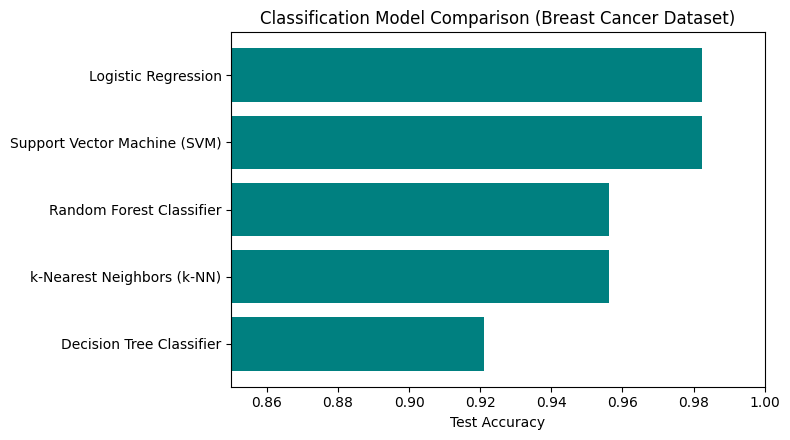

In [16]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree Classifier": DecisionTreeClassifier(
        max_depth=5, random_state=42
    ),
    "Random Forest Classifier": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),
    "Support Vector Machine (SVM)": SVC(kernel="rbf", random_state=42),
    "k-Nearest Neighbors (k-NN)": KNeighborsClassifier(n_neighbors=5),
}

# 3. Evaluate each model across multiple metrics
comparison_rows = []

for name, model in models.items():
  if name in [
      "Logistic Regression",
      "Support Vector Machine (SVM)",
      "k-Nearest Neighbors (k-NN)",
  ]:
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
  else:
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

  # Compute confusion matrix counts: TN, FP, FN, TP
  tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

  comparison_rows.append({
      "Model": name,
      "Accuracy": round(accuracy_score(y_test, y_pred), 4),
      "Precision": round(precision_score(y_test, y_pred), 4),
      "Recall": round(recall_score(y_test, y_pred), 4),
      "F1-Score": round(f1_score(y_test, y_pred), 4),
      "False Negatives (FN)": fn,
      "False Positives (FP)": fp,
  })

# Sort from highest to lowest accuracy
comparison_df = pd.DataFrame(comparison_rows).sort_values(
    by="Accuracy", ascending=False
)

print("=== Model Comparison Table ===")
print(comparison_df.to_string(index=False))

# Identify best and worst performing models by Accuracy (and F1 as tie-breaker)
best_row = comparison_df.iloc[0]
worst_row = comparison_df.iloc[-1]

print(
    f"\nBest Performing Algorithm:  {best_row['Model']} "
    f"(Accuracy={best_row['Accuracy']}, F1={best_row['F1-Score']})"
)
print(
    f"Worst Performing Algorithm: {worst_row['Model']} "
    f"(Accuracy={worst_row['Accuracy']}, F1={worst_row['F1-Score']})"
)

# 4. Visual bar chart comparing test accuracy across all 5 models
plt.figure(figsize=(8, 4.5))
plt.barh(
    comparison_df["Model"], comparison_df["Accuracy"], color="teal"
)
plt.xlabel("Test Accuracy")
plt.title("Classification Model Comparison (Breast Cancer Dataset)")
plt.xlim(0.85, 1.0)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()